# Почему опаздывает доставка «Зерна»

In [1]:
import math
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
RANDOM_STATE=42
DATA=Path("../data")
print(pd.__version__,matplotlib.__version__)

3.0.6 3.10.9


## 1. Цель

Руководителю доставки нужно решить, стоит ли менять сроки для части заказов. Метрика — доля доставок, в которых зарегистрированное время превысило обещанное.

**Главное.** Позже обещанного приехали 441 из 1841 доставок (24.0 %). На пеших маршрутах с обещанием 30 минут доля равна 69.7 %. Предлагаем проверить обещание 40 минут на сопоставимых маршрутах и отслеживать конверсию заказов.

## 2. Данные

In [2]:
raw=pd.read_csv(DATA/"deliveries.csv",parse_dates=["created"])
print(raw.shape,raw.created.min(),raw.created.max())
raw.head(3)

(1877, 11) 2026-09-01 11:43:00 2026-11-30 21:32:00


,delivery_id,created,shop_id,courier,distance_km,weather,items,amount,promised_min,actual_min,rating
0,DL-00001,2026-09-01 11:43:00,PRM-2,пеший,1.1,ясно,6,1527,30,31.0,NaN
1,DL-00002,2026-09-01 13:06:00,PRM-1,авто,4.2,облачно,5,1172,45,37.0,5.0
2,DL-00003,2026-09-01 13:12:00,PRM-1,вело,4.6,ясно,2,522,45,44.0,NaN


**Вывод.** Проанализирована вся осенняя выгрузка из 1877 доставок. Есть фактическое время, обещание, тип курьера, условия маршрута и оценка гостя.

## 3. Предобработка

In [3]:
valid=raw.actual_min.between(1,299)
ok=raw[valid].copy()
ok["late"]=ok.actual_min>ok.promised_min
ok["delay"]=ok.actual_min-ok.promised_min
ok["hour"]=ok.created.dt.hour
log={"всего":len(raw),"без времени":raw.actual_min.isna().sum(),"невозможное время":(raw.actual_min.notna()&~valid).sum(),"осталось":len(ok)}
pd.Series(log,name="доставки")

всего                1877
без времени            25
невозможное время      11
осталось             1841
Name: доставки, dtype: int64

**Вывод.** Из 1877 строк исключены 25 без фактического времени и 11 с невозможным временем. Осталось 1841. Для пропущенных срок выполнения неизвестен.

## 4.1. Масштаб опозданий

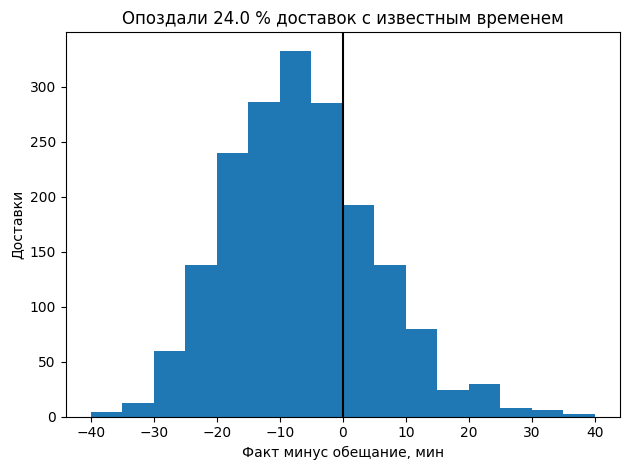

In [4]:
v=ok.loc[ok.late,"delay"]
late_pct=round(ok.late.mean()*100,1)
late_median=v.median()
p90_late=v.quantile(.9)
fig,ax=plt.subplots()
ax.hist(ok.delay,bins=range(-40,41,5))
ax.axvline(0,color="black")
ax.set(xlabel="Факт минус обещание, мин",ylabel="Доставки",title=f"Опоздали {late_pct:.1f} % доставок с известным временем")
plt.tight_layout()
plt.show()

**Вывод.** Опоздали 441 из 1841. У половины опоздавших превышение не больше 7 минут, у 90 % — не больше 20. Если все исключённые строки были либо вовремя, либо с опозданием, доля во всей выгрузке лежит между 23.5 и 25.4 %.

## 4.2. Срезы с группами от 50 доставок

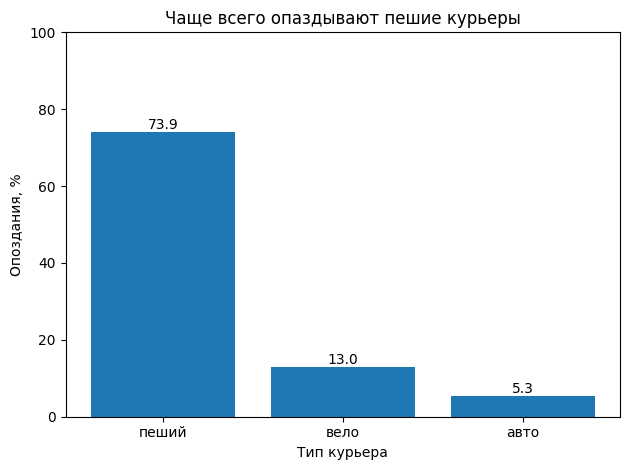

courier    68.6
items      22.3
hour       20.9
weather    15.0
shop_id    13.1
dtype: float64

In [5]:
res={}
for k in ["courier","weather","shop_id","items","hour"]:
    v=ok.groupby(k).late.agg(["size","mean"])
    v=v.loc[v["size"]>=50,"mean"]
    res[k]=100*(v.max()-v.min())
ranking=pd.Series(res).sort_values(ascending=False).round(1)
top_factor=ranking.idxmax()
v=(100*ok.groupby(top_factor).late.mean()).sort_values(ascending=False)
fig,ax=plt.subplots()
bars=ax.bar(v.index,v.values)
ax.bar_label(bars,fmt="%.1f")
ax.set(xlabel="Тип курьера",ylabel="Опоздания, %",title="Чаще всего опаздывают пешие курьеры")
ax.set_ylim(0,100)
plt.tight_layout()
plt.show()
ranking

**Вывод.** Наибольший разрыв между устойчиво представленными группами — по типу курьера, 68.6 п. п. Маршруты и условия заказа могут различаться между типами.

## 4.3. Обещание пешеходам

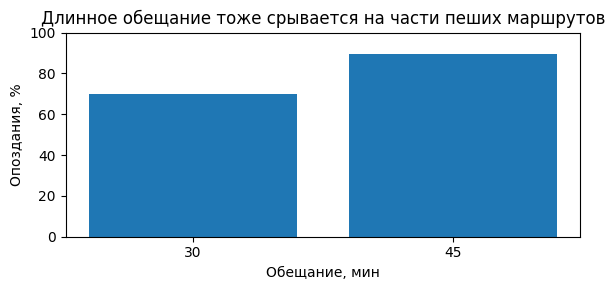

courier,авто,вело,пеший
promised_min,,,
30,17.6,24.4,69.7
45,1.4,7.8,89.5
60,4.3,21.4,NaN


In [6]:
pv=ok.pivot_table(index="promised_min",columns="courier",values="late",aggfunc="mean")*100
w=ok[ok.courier=="пеший"]
walk_p80=w.loc[w.promised_min==30,"actual_min"].quantile(.8)
fair_promise=math.ceil(walk_p80/5)*5
w45=w[w.promised_min==45]
walk45_km=w45.distance_km.median()
walk45_min=w45.actual_min.median()
v=pv["пеший"].dropna()
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(v.index.astype(str),v)
ax.set(xlabel="Обещание, мин",ylabel="Опоздания, %",ylim=(0,100),title="Длинное обещание тоже срывается на части пеших маршрутов")
plt.tight_layout()
plt.show()
pv.round(1)

**Вывод.** Из 317 пеших доставок с обещанием 30 минут опоздали 69.7 %. P80 факта — 40.0 мин. Для тех же маршрутов ориентир после округления вверх — 40 мин. У пеших с обещанием 45 минут медианы расстояния и фактического времени — 3.0 км и 60 минут.

## 4.4. Кофейня KZN-2

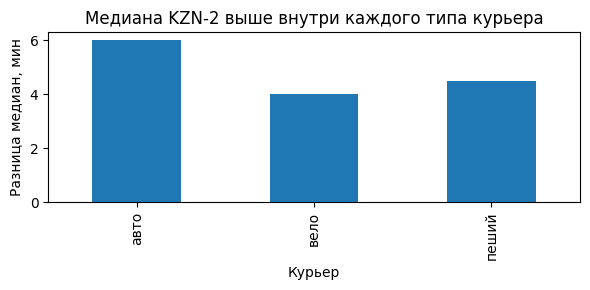

,минуты,километры
авто,6.0,0.1
вело,4.0,-0.1
пеший,4.5,0.0


In [7]:
ok["kzn2"] = ok["shop_id"] == "KZN-2"
g=ok.groupby(["courier","kzn2"])
v=g.actual_min.median().unstack()
dist=g.distance_km.median().unstack()
kzn2_gap=(v[True]-v[False]).to_dict()
same_distance=(dist[True]-dist[False]).round(1).to_dict()
t=pd.Series(kzn2_gap)
ax=t.plot.bar(figsize=(6,3))
ax.set(title="Медиана KZN-2 выше внутри каждого типа курьера",xlabel="Курьер",ylabel="Разница медиан, мин")
plt.tight_layout()
plt.show()
pd.DataFrame({"минуты":kzn2_gap,"километры":same_distance})

**Вывод.** Разница медианного времени KZN-2 и остальных точек по типам — авто 6 мин, вело 4 мин, пеший 4.5 мин. Проверить загрузку кухни и ожидание выдачи заказа до изменения нормативов.

## 4.5. Снег и динамика

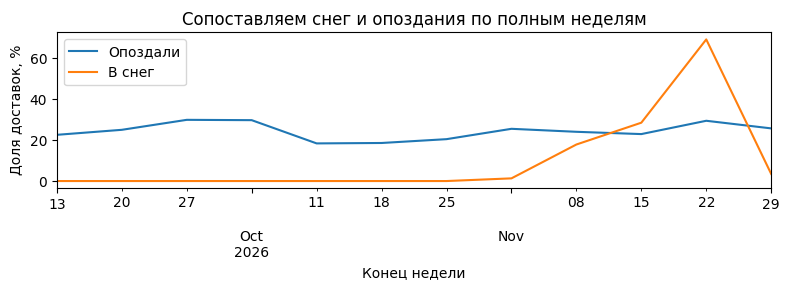

In [8]:
ok["snow"] = ok["weather"] == "снег"
weeks=ok.set_index("created").resample("W")[["late","snow"]].mean().iloc[1:-1]*100
weeks.columns=["late_pct","snow_pct"]
r_weeks=round(weeks.late_pct.corr(weeks.snow_pct),2)

ax=weeks.rename(columns={"late_pct":"Опоздали","snow_pct":"В снег"}).plot(figsize=(8,3))
ax.set(title="Сопоставляем снег и опоздания по полным неделям",xlabel="Конец недели",ylabel="Доля доставок, %")
plt.tight_layout()
plt.show()

**Вывод.** Корреляция долей снега и опозданий по 12 полным неделям — 0.34. Недель мало, на данные могут влиять и изменения состава курьеров.

## 4.6. Оценки гостей

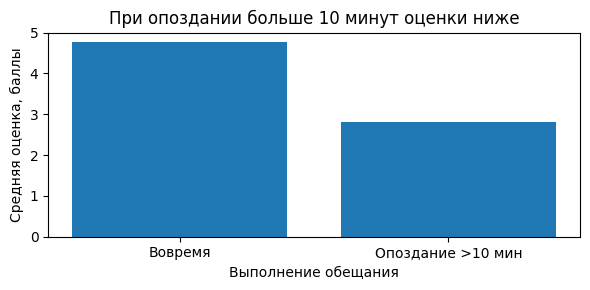

In [9]:
v=ok.loc[ok.delay>10,"rating"].dropna()
rating_on_time=round(ok.loc[~ok.late,"rating"].mean(),2)
rating_late10=round(v.mean(),2)
low_share_late10=round((v<=3).mean()*100,1)
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(["Вовремя","Опоздание >10 мин"],[rating_on_time,rating_late10])
ax.set(xlabel="Выполнение обещания",ylabel="Средняя оценка, баллы",ylim=(0,5),title="При опоздании больше 10 минут оценки ниже")
plt.tight_layout()
plt.show()

**Вывод.** По оставленным отзывам средняя оценка вовремя — 4.77, при опоздании больше 10 минут — 2.80. Среди 75 оценок в последней группе 70.7 % составляют оценки до трёх включительно. Гости без оценки в знаменатель не входят.

## 4.7. Две дополнительные закономерности

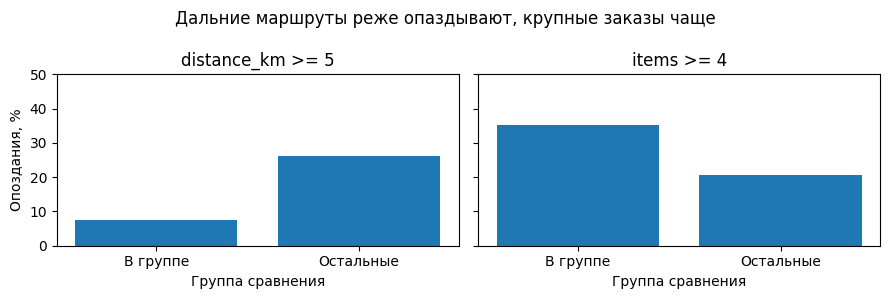

                   mean  size
courier                      
авто    False  0.057895   380
        True   0.043011   186
вело    False  0.125301   830
        True   0.214286    42
пеший   False  0.739454   403
                   mean  size
courier                      
авто    False  0.036117   443
        True   0.113821   123
вело    False  0.106725   684
        True   0.212766   188
пеший   False  0.692568   296
        True   0.869159   107


In [10]:
findings=[]
for rule,meaning,limit in [("distance_km >= 5","На дальних маршрутах ниже наблюдаемая доля опозданий","Пеших в этой группе нет, а среди велокурьеров зависимость обратная."),("items >= 4","Большие заказы чаще опаздывают","Разница есть у каждого типа курьера, но время сборки отдельно неизвестно.")]:
    a=ok.query(rule)
    b=ok.loc[~ok.index.isin(a.index)]
    x,y=round(a.late.mean()*100,1),round(b.late.mean()*100,1)
    findings.append({"группа":rule,"n":len(a),"late_pct":x,"остальные_pct":y,"вывод":f"{meaning}: {x}% для {len(a)} доставок, {y}% для остальных {len(b)}. {limit}"})
fig,axes=plt.subplots(1,2,figsize=(9,3),sharey=True)
for ax,item in zip(axes,findings):
    ax.bar(["В группе","Остальные"],[item["late_pct"],item["остальные_pct"]])
    ax.set(title=item["группа"],xlabel="Группа сравнения",ylim=(0,50))
axes[0].set_ylabel("Опоздания, %")
fig.suptitle("Дальние маршруты реже опаздывают, крупные заказы чаще")
plt.tight_layout()
plt.show()
for rule in ["distance_km >= 5","items >= 4"]:
    print(ok.groupby(["courier",ok.index.isin(ok.query(rule).index)]).late.agg(["mean","size"]))

**Вывод.** На дальних маршрутах ниже наблюдаемая доля опозданий: 7.5% для 228 доставок, 26.3% для остальных 1613. Пеших в этой группе нет, а среди велокурьеров зависимость обратная.

Большие заказы чаще опаздывают: 35.2% для 418 доставок, 20.7% для остальных 1423. Разница есть у каждого типа курьера, но время сборки отдельно неизвестно.

## 5. Выводы и рекомендации

In [11]:
def delivery_report(raw):
    ok=raw[raw.actual_min.between(1,299)].copy()
    ok["late"]=ok.actual_min>ok.promised_min
    g=ok.groupby(ok.created.dt.hour).late.agg(["mean","size"])
    w=ok[(ok.courier=="пеший")&(ok.promised_min==30)].actual_min
    return {"late_pct":round(ok.late.mean()*100,1),"worst_courier":ok.groupby("courier").late.mean().idxmax() if len(ok) else None,
            "worst_shop":ok.groupby("shop_id").late.mean().idxmax() if len(ok) else None,
            "peak_hours":g.index[(g["size"]>=50)&(g["mean"]>.25)].tolist(),"fair_promise":math.ceil(w.quantile(.8)/5)*5 if len(w) else None}


print(delivery_report(raw))
print(delivery_report(raw[raw.created.dt.month==11]))

{'late_pct': np.float64(24.0), 'worst_courier': 'пеший', 'worst_shop': 'KZN-2', 'peak_hours': [12, 13, 18, 19], 'fair_promise': 40}
{'late_pct': np.float64(25.8), 'worst_courier': 'пеший', 'worst_shop': 'KZN-2', 'peak_hours': [12, 13, 18, 19], 'fair_promise': 45}


**Решение.** Начать с пилота срока 40 минут для пеших маршрутов, которым обещали 30. Сравнить с контролем долю опозданий, конверсию и оценку. Для KZN-2 замерить интервал между готовностью и передачей курьеру. Заказы с четырьмя и более позициями изучить отдельно по времени сборки.

**Ограничения.** Оценки есть не у всех гостей. Снег, выбор транспорта и маршрут связаны между собой. Данные охватывают одну осень. При планировании ресурсов сохранить отдельные знаменатели по точкам, типам курьеров и обещаниям.